# Brain Stroke V4
**CustomCNN • ResNet50 • VGG16 • VGG19 — Kaggle.**

Notebook cho dataset ảnh CT 2D có hai thư mục `Normal/Stroke`, không phải pipeline MRI,
DICOM/NIfTI hay phân đoạn APIS/ISLES. Nhãn được lấy nguyên từ thư mục: Normal=0, Stroke=1.
Không tự sửa nhãn, không gán điểm đánh giá, không có kết quả huấn luyện sẵn.

## Học trọng số khác với chọn ngưỡng
- Cả bốn mô hình học bằng `fit`: tối thiểu hóa binary cross-entropy trên TRAIN.
  Ba mạng transfer learning dùng ImageNet, học head rồi fine-tuning các block cuối.
- Checkpoint và kiến trúc chọn bằng VALIDATION PR-AUC/AP. Không dùng TEST để chọn.
- **Mặc định ngưỡng 0,5**, đặt trước huấn luyện, giống nhau khi báo cáo và chạy local.
  Bỏ hoàn toàn hàm tìm ngưỡng tối đa F1. Không dò ngưỡng theo validation hay test.
  Ngưỡng là quy tắc đổi điểm thành nhãn, không phải mức Accuracy yêu cầu hay độ chắc chắn lâm sàng.
- 0,5 là mốc so sánh, không khẳng định tối ưu cho mọi nhiệm vụ. Nếu nghiên cứu sau cần giảm bỏ sót,
  hãy định nghĩa mục tiêu trước, chọn ngưỡng bằng validation độc lập và công khai đánh đổi FP/FN.
  Không điều chỉnh trên test đã xem. Notebook này không thực hiện bước đó.
- ROC-AUC và Average Precision (AP) đánh giá thứ tự điểm, không phụ thuộc một ngưỡng duy nhất.
  Accuracy, Precision, Recall, F1, MCC, Specificity, FPR phụ thuộc ngưỡng được công bố.

## Quy trình và giới hạn
Chia train/val/test mục tiêu 70/15/15 trước augmentation; shuffle toàn bộ đường dẫn train;
augmentation chỉ train; class weights tính từ train và đưa vào loss, không sửa điểm dự đoán.
Mỗi kiến trúc huấn luyện một lần, không ensemble, không thử seed để chọn điểm đẹp.
Giữ kiến trúc, LR và giới hạn epoch V3 để không trộn thay đổi mô hình với thay đổi cách báo cáo.
V4 làm rõ quy trình, **không cam kết cải thiện Accuracy**. Nếu giữ cùng split/seed, điểm có thể gần V3.

Không có patient ID thì chỉ chia theo ảnh đã loại trùng pixel; chưa bảo đảm độc lập bệnh nhân.
Ảnh gần trùng hoặc lát cắt cùng bệnh nhân có thể giao giữa các tập dù hash không trùng.
Test cũ đã được xem trong quá trình phát triển: cần tập ngoài chưa xem để đánh giá cuối.
Nhãn dataset theo ca không bảo đảm lát cắt nào cũng thấy tổn thương; học nhãn ảnh chưa chứng minh học đúng tổn thương.
Đây là nghiên cứu phân loại dữ liệu, chưa phải công cụ chẩn đoán.

## Chạy trên Kaggle
1. Import notebook này; Add Input **dataset gốc Normal/Stroke**, bật GPU và Internet.
2. Chạy Cell 1→6, kiểm tra đường dẫn, ảnh mẫu, số ảnh, phép chia và batch nhãn.
3. Chạy Cell 7 để huấn luyện cả bốn model; Cell 8 để đánh giá test một lần.
4. Cell 9 xem lỗi; chạy **đủ ba ô code của Cell 10** để xuất model/config/script/ZIP.
5. Nếu so với V3 theo cùng ảnh, Add Input `split_manifest.csv` V3 và đặt
   `SPLIT_MANIFEST_OVERRIDE` ở Cell 1. Không tự tạo phép chia mới để tìm điểm cao hơn.


## Cell 1 — Cấu hình và môi trường
Giữ TensorFlow có sẵn của Kaggle; không pip cài đè TensorFlow. RGB 224×224, batch 16, một GPU.
Chạy đủ 4 model lâu hơn V2. Đây là giới hạn epoch, EarlyStopping có thể dừng sớm.
Không tái sử dụng OUT đã bắt đầu train: giữ riêng thí nghiệm để tránh trộn checkpoint.


In [1]:
import os, json, gc, time, hashlib, shutil, sys, platform, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
import tensorflow as tf
from tensorflow.keras import layers as L
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (log_loss, accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, matthews_corrcoef, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS_CNN, EPOCHS_HEAD, EPOCHS_FINE = 60, 10, 40
MODELS_TO_TRAIN = ['CustomCNN', 'ResNet50', 'VGG16', 'VGG19']
DATA_DIR_OVERRIDE = ''  # Ví dụ /kaggle/input/your-dataset/Brain_Data_Organised
ZIP_PATH_OVERRIDE = ''  # Chỉ điền nếu dataset còn nằm trong ZIP.
SPLIT_MANIFEST_OVERRIDE = ''  # Điền manifest V3 để so trên đúng cùng ảnh; không đoán theo số lượng.
PATIENT_CSV = ''  # Nếu có: CSV với cột relpath,patient_id; relpath tính từ DATA_DIR.
# Không tự đoán patient_id từ tên ảnh như '50 (26).jpg'.
REQUIRE_GPU = True
USE_CLASS_WEIGHT = True
# Chốt trước khi chạy, không tự tìm ngưỡng. Mặc định đề xuất cho so sánh bốn mạng.
# Chỉ đổi khi có thiết kế thí nghiệm định trước; không đổi sau khi xem test.
DECISION_THRESHOLD = 0.5
assert 0.0 < DECISION_THRESHOLD < 1.0
# Pipeline không cache toàn bộ ảnh float32 trong RAM.
OUT = Path('/kaggle/working/brain_stroke_v4') if Path('/kaggle/working').exists() else Path('brain_stroke_v4')
OUT.mkdir(parents=True, exist_ok=True)
if (OUT/'RUN_STARTED.json').exists():
    raise RuntimeError('Thư mục output đã có lần chạy trước. Đổi OUT sang tên mới để tránh trộn checkpoint/báo cáo.')
assert len(MODELS_TO_TRAIN) == len(set(MODELS_TO_TRAIN)) > 0
assert set(MODELS_TO_TRAIN) <= {'CustomCNN', 'ResNet50', 'VGG16', 'VGG19'}
tf.keras.utils.set_random_seed(SEED)
gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
if REQUIRE_GPU and not gpus:
    raise RuntimeError('Chưa có GPU. Bật GPU trong cài đặt Kaggle rồi khởi động lại phiên.')
# float32 giúp dễ kiểm tra pipeline; chưa dùng mixed precision/multi-GPU.
tf.keras.mixed_precision.set_global_policy('float32')
# Bỏ riêng phép tối ưu layout; vẫn sử dụng GPU để train, không che log lỗi.
tf.config.optimizer.set_experimental_options({'layout_optimizer': False})
try:
    tf.config.experimental.enable_op_determinism()
except AttributeError:
    print('TensorFlow này không hỗ trợ enable_op_determinism.')
AUTOTUNE = tf.data.AUTOTUNE
env = dict(python=sys.version, tensorflow=tf.__version__, keras=getattr(tf.keras,'__version__','unknown'),
           numpy=np.__version__, platform=platform.platform(), GPU=[str(g) for g in gpus])
(OUT/'environment.json').write_text(json.dumps(env, indent=2), encoding='utf-8')
print(json.dumps(env, indent=2))
print('Output:', OUT)
print('Ngưỡng đã chốt trước huấn luyện:', DECISION_THRESHOLD)


{
  "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]",
  "tensorflow": "2.20.0",
  "keras": "3.13.2",
  "numpy": "2.1.3",
  "platform": "Linux-6.18.48+-x86_64-with-glibc2.39",
  "GPU": [
    "PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')",
    "PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')"
  ]
}
Output: /kaggle/working/brain_stroke_v4
Ngưỡng đã chốt trước huấn luyện: 0.5


## Cell 2 — Tìm dataset gốc
Chỉ chấp nhận một cặp thư mục Normal/Stroke. Nếu có nhiều ứng viên, dừng để bạn chọn, không tự chọn nhầm dataset.
ZIP được kiểm tra đường dẫn và dung lượng trước khi giải nén. Không upload ZIP model vào vị trí dataset.


In [2]:
INPUT_ROOT = Path('/kaggle/input')
def find_roots(root):
    found = []
    for current, dirs, _ in os.walk(root):
        if 'Normal' in dirs and 'Stroke' in dirs:
            found.append(Path(current)); dirs[:] = []
    return sorted(found)

if DATA_DIR_OVERRIDE:
    DATA_DIR = Path(DATA_DIR_OVERRIDE)
else:
    candidates = find_roots(INPUT_ROOT)
    if not candidates:
        archives = [Path(ZIP_PATH_OVERRIDE)] if ZIP_PATH_OVERRIDE else sorted(INPUT_ROOT.rglob('*.zip'))
        if len(archives) != 1:
            raise FileNotFoundError('Chưa thấy Normal/Stroke. Add Input dữ liệu gốc; nếu nhiều ZIP, điền ZIP_PATH_OVERRIDE. ZIP tìm thấy: '+str(archives))
        extract_root = OUT/'extracted_data'
        extract_root.mkdir(exist_ok=True)
        with zipfile.ZipFile(archives[0]) as archive:
            for info in archive.infolist():
                target = (extract_root/info.filename).resolve()
                if not target.is_relative_to(extract_root.resolve()):
                    raise ValueError('ZIP có đường dẫn vượt thư mục: '+info.filename)
            need = sum(info.file_size for info in archive.infolist())
            if need > shutil.disk_usage(OUT).free * 0.8:
                raise RuntimeError('Không đủ dung lượng an toàn để giải nén ZIP và lưu model.')
            archive.extractall(extract_root)
        candidates = find_roots(extract_root)
    if len(candidates) != 1:
        raise ValueError('Điền DATA_DIR_OVERRIDE bằng đúng một thư mục trong danh sách: '+str(candidates))
    DATA_DIR = candidates[0]
assert all((DATA_DIR/c).is_dir() for c in ['Normal','Stroke']), 'Sai DATA_DIR.'
print('DATA_DIR =', DATA_DIR)


DATA_DIR = /kaggle/input/datasets/afridirahman/brain-stroke-ct-image-dataset/Brain_Data_Organised


## Cell 3 — Kiểm tra ảnh, nhãn và bản sao
Chỉ nhận ảnh tĩnh 8-bit. Ảnh 16-bit/float/multiframe bị loại kèm lý do, không tự window CT hay ép về 8-bit.
JPEG/PNG/BMP được giải mã bằng TensorFlow; TIFF/WebP chuyển **PNG không mất thêm thông tin** để pipeline thống nhất.
Không xoay EXIF, không crop, không chỉnh tương phản riêng khi inference.
Hash được tính trên pixel RGB sau giải mã, trước resize. Bản sao pixel cùng nhãn giữ một đại diện;
nếu cùng pixel khác nhãn, dừng để sửa dữ liệu nguồn. Hash không phát hiện hết ảnh gần trùng/ảnh cùng bệnh nhân.


I0000 00:00:1792635960.722508      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792635960.725783      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Đã kiểm tra 500/2501 ảnh
Đã kiểm tra 1000/2501 ảnh
Đã kiểm tra 1500/2501 ảnh
Đã kiểm tra 2000/2501 ảnh
Đã kiểm tra 2500/2501 ảnh
Ảnh hợp lệ: 2501 Ảnh bị loại: 0 Ảnh trong nhóm trùng: 0


,so_anh,rong_min,rong_max
class,,,
Normal,1551,650,650
Stroke,950,650,650


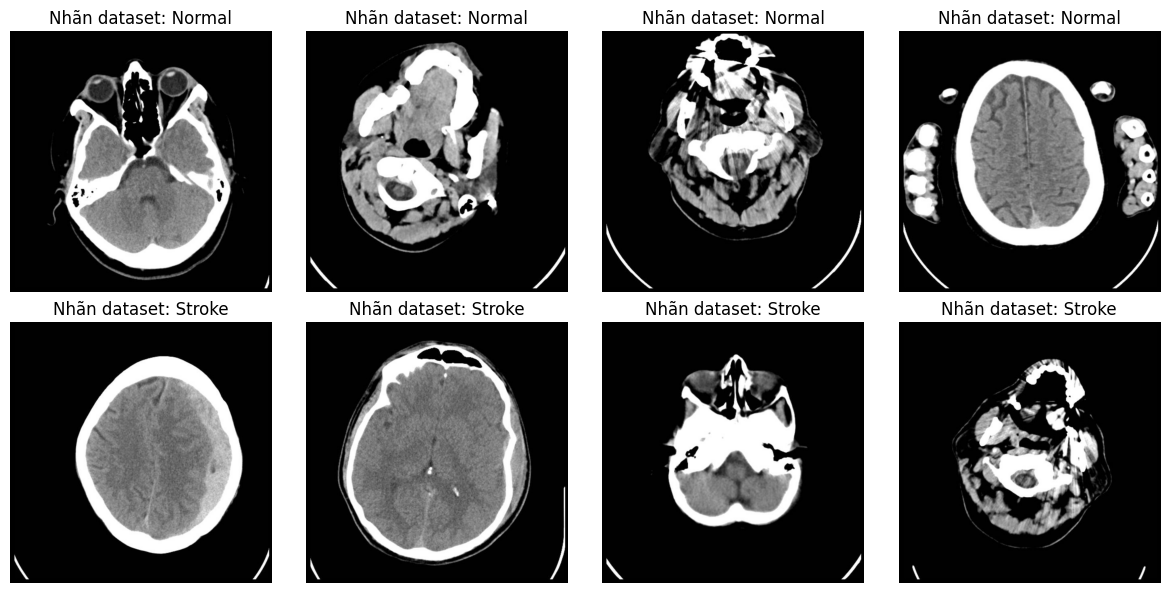

In [3]:
EXTS = {'.jpg','.jpeg','.png','.bmp','.tif','.tiff','.webp'}
converted = OUT/'converted'; converted.mkdir(exist_ok=True)
records, rejected = [], []
all_paths = [(label, cls, p) for label,cls in [(0,'Normal'),(1,'Stroke')]
             for p in sorted((DATA_DIR/cls).rglob('*')) if p.is_file() and p.suffix.lower() in EXTS]
for i,(label,cls,p) in enumerate(all_paths):
    relpath = p.relative_to(DATA_DIR).as_posix()
    try:
        with Image.open(p) as im:
            if getattr(im,'n_frames',1) != 1 or im.mode in ('I','F') or im.mode.startswith('I;16'):
                raise ValueError('Ảnh đa frame hoặc 16-bit/float, cần pipeline riêng.')
            im.load()
            width,height = im.size
            mode = im.mode
            orientation = int(im.getexif().get(274,1))
            input_path = p
            if im.format not in ('JPEG','PNG','BMP'):
                input_path = converted/(hashlib.sha256(relpath.encode()).hexdigest()+'.png')
                im.convert('RGB').save(input_path)
        pixels = tf.io.decode_image(tf.io.read_file(str(input_path)), channels=3, expand_animations=False)
        arr = pixels.numpy()
        if arr.ndim != 3 or arr.shape[-1] != 3 or arr.dtype != np.uint8:
            raise ValueError('Đầu vào không phải RGB uint8.')
        digest = hashlib.sha256(np.asarray(arr.shape,dtype='<i8').tobytes()+arr.tobytes()).hexdigest()
        records.append(dict(path=str(input_path), original_path=str(p), relpath=relpath,
                            label=label, **{'class':cls}, width=width,height=height,mode=mode,
                            exif_orientation=orientation, pixel_sha256=digest))
    except Exception as exc:
        rejected.append(dict(relpath=relpath,reason=f'{type(exc).__name__}: {exc}'))
    if (i+1)%500 == 0:
        print(f'Đã kiểm tra {i+1}/{len(all_paths)} ảnh')
df_all = pd.DataFrame(records)
pd.DataFrame(rejected,columns=['relpath','reason']).to_csv(OUT/'rejected_images.csv',index=False)
if df_all.empty or df_all.label.nunique()!=2:
    raise ValueError('Cần ảnh hợp lệ ở cả hai lớp. Xem rejected_images.csv.')
df_all.to_csv(OUT/'all_valid_images.csv',index=False)
conflict_hashes = df_all.groupby('pixel_sha256').label.nunique()
conflict_hashes = conflict_hashes[conflict_hashes>1].index
if len(conflict_hashes):
    df_all[df_all.pixel_sha256.isin(conflict_hashes)].to_csv(OUT/'label_conflicts.csv',index=False)
    raise ValueError('Cùng pixel nhưng nhãn khác nhau: xem label_conflicts.csv. Không tự sửa nhãn.')
duplicates = df_all[df_all.duplicated('pixel_sha256',keep=False)]
duplicates.to_csv(OUT/'duplicate_pixels.csv',index=False)
print('Ảnh hợp lệ:',len(df_all),'Ảnh bị loại:',len(rejected),'Ảnh trong nhóm trùng:',len(duplicates))
if len(rejected):
    display(pd.DataFrame(rejected).head(10))
display(df_all.groupby('class').agg(so_anh=('path','size'),rong_min=('width','min'),rong_max=('width','max')))
fig,axs = plt.subplots(2,4,figsize=(12,6))
for row,cls in enumerate(['Normal','Stroke']):
    subset = df_all[df_all['class']==cls].sample(n=min(4,sum(df_all['class']==cls)),random_state=SEED)
    for ax in axs[row]: ax.axis('off')
    for ax,p in zip(axs[row],subset.path):
        ax.imshow(tf.io.decode_image(tf.io.read_file(p),channels=3,expand_animations=False).numpy())
        ax.set_title('Nhãn dataset: '+cls)
plt.tight_layout(); plt.savefig(OUT/'dataset_examples.png'); plt.show()


## Cell 4 — Chia Train / Validation / Test, kiểm tra không giao nhau
Mục tiêu 70/15/15 theo nhóm; tỷ lệ theo số ảnh có thể chênh khi nhóm khác kích thước.
Nếu có `PATIENT_CSV`, mọi ảnh phải được ánh xạ `relpath,patient_id`; liên kết nhóm bệnh nhân và bản sao pixel
trước khi chia. Một nhóm có cả nhãn Normal/Stroke sẽ dừng để kiểm tra, không tự đoán.
Nếu không có metadata, chia theo ảnh đã loại trùng pixel và ghi rõ giới hạn đó trong báo cáo.
Không suy patient ID từ số trong tên file.

Nếu cung cấp manifest lần trước, đối chiếu đầy đủ hash và nhãn rồi dùng lại split; vẫn kiểm tra độc lập nhóm/bệnh nhân. Nếu manifest cũ chia cắt patient ID mới cung cấp, dừng thay vì chấp nhận rò rỉ.


In [4]:
# Union-find nối bệnh nhân và bản sao, kể cả bản sao nằm ở hai patient ID khác nhau.
parent = list(range(len(df_all)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
def union(i,j):
    a,b = find(i),find(j)
    if a!=b: parent[b]=a
if PATIENT_CSV:
    patient = pd.read_csv(PATIENT_CSV,dtype=str,keep_default_na=False)
    assert {'relpath','patient_id'} <= set(patient.columns), 'CSV cần relpath,patient_id.'
    patient['relpath'] = patient.relpath.str.replace('\\','/',regex=False)
    assert not patient.relpath.duplicated().any(), 'Metadata trùng relpath.'
    df_all = df_all.merge(patient[['relpath','patient_id']],on='relpath',how='left',validate='one_to_one')
    assert df_all.patient_id.notna().all() and df_all.patient_id.str.strip().ne('').all(), 'Thiếu patient_id.'
    for _,indices in df_all.groupby('patient_id').groups.items():
        indices = list(indices)
        for j in indices[1:]: union(indices[0],j)
    split_scope = 'patient_and_exact_pixel_groups'
else:
    split_scope = 'deduplicated_image_only_NOT_patient_independent'
    print('CẢNH BÁO: chưa có patient ID; không thể bảo đảm độc lập bệnh nhân.')
for _,indices in df_all.groupby('pixel_sha256').groups.items():
    indices = list(indices)
    for j in indices[1:]: union(indices[0],j)
df_all['group_id'] = [str(find(i)) for i in range(len(df_all))]
df = df_all.drop_duplicates('pixel_sha256',keep='first').copy().reset_index(drop=True)
assert df.groupby('group_id').label.nunique().max()==1, 'Nhóm bệnh nhân/bản sao có nhãn xung đột; kiểm tra nguồn.'
units = df.groupby('group_id',as_index=False).agg(label=('label','first'))
if units.groupby('label').size().min()<10:
    raise ValueError('Quá ít nhóm độc lập ở một lớp để chia phân tầng 3 tập. Cần thiết kế chia khác trước khi train.')

if SPLIT_MANIFEST_OVERRIDE:
    old = pd.read_csv(SPLIT_MANIFEST_OVERRIDE,dtype={'pixel_sha256':str,'split':str})
    assert {'pixel_sha256','label','split'}<=set(old), 'Manifest cần pixel_sha256,label,split.'
    assert not old.pixel_sha256.duplicated().any(), 'Manifest phải có một hàng cho mỗi hash.'
    assert len(old)==len(df) and set(old.pixel_sha256)==set(df.pixel_sha256), 'Dataset/hash khác manifest: không tự đổi phép chia.'
    old = old[['pixel_sha256','label','split']].rename(columns={'label':'old_label'})
    df = df.merge(old,on='pixel_sha256',how='left',validate='one_to_one')
    assert df.label.eq(df.old_label).all(), 'Nhãn nguồn khác manifest cũ.'
    assert set(df.split)=={'train','val','test'}, 'Tên split cần train,val,test.'
    assert df.groupby('group_id').split.nunique().max()==1, 'Manifest cũ chia cắt một nhóm bệnh nhân/bản sao.'
    df = df.drop(columns='old_label')
    print('Đã khóa split theo hash của manifest cung cấp.')
else:
    train_units,temp_units = train_test_split(units,test_size=0.30,stratify=units.label,random_state=SEED)
    val_units,test_units = train_test_split(temp_units,test_size=0.50,stratify=temp_units.label,random_state=SEED)
    mapping = {g:split for split,u in [('train',train_units),('val',val_units),('test',test_units)] for g in u.group_id}
    df['split'] = df.group_id.map(mapping)
mapping = df.groupby('group_id').split.first().to_dict()
train_df = df[df.split=='train'].reset_index(drop=True)
val_df = df[df.split=='val'].reset_index(drop=True)
test_df = df[df.split=='test'].reset_index(drop=True)
parts = {'train':train_df,'val':val_df,'test':test_df}
for name,part in parts.items():
    assert part.label.nunique()==2, f'{name} thiếu một lớp.'
    part.to_csv(OUT/f'{name}_files.csv',index=False)
for key in ['pixel_sha256','group_id'] + (['patient_id'] if PATIENT_CSV else []):
    for a,b in [('train','val'),('train','test'),('val','test')]:
        assert set(parts[a][key]).isdisjoint(parts[b][key]), f'Rò rỉ {key}: {a}/{b}'
df.to_csv(OUT/'split_manifest.csv',index=False)
df_all['split'] = df_all.group_id.map(mapping)
df_all.to_csv(OUT/'all_images_with_groups.csv',index=False)
split_summary = df.groupby(['split','class']).size().unstack(fill_value=0)
display(split_summary)
split_summary.to_csv(OUT/'split_summary.csv')
print('Phạm vi đánh giá:',split_scope)


CẢNH BÁO: chưa có patient ID; không thể bảo đảm độc lập bệnh nhân.


class,Normal,Stroke
split,,
test,233,143
train,1085,665
val,233,142


Phạm vi đánh giá: deduplicated_image_only_NOT_patient_independent


## Cell 5 — Shuffle toàn bộ đường dẫn trước decode + audit batch
Sửa trực tiếp điểm yếu của V2: buffer chứa đường dẫn/nhãn, không chứa toàn bộ tensor ảnh.
Validation/test không shuffle để ghép dự đoán đúng nhãn. Augmentation nằm trong model, chỉ bật khi train.
Audit là kiểm tra nhãn dữ liệu thật; batch không bị ép có tỷ lệ cố định và không gán dự đoán.
Không dừng chỉ vì một batch tình cờ có một lớp. `group_id` là nhóm kỹ thuật, không tự suy ra patient ID.


In [5]:
def decode_img(path,label):
    image = tf.io.decode_image(tf.io.read_file(path),channels=3,expand_animations=False)
    image.set_shape((None,None,3))
    image = tf.image.resize(image,IMG_SIZE,method='bilinear',antialias=False)
    return tf.cast(image,tf.float32),tf.reshape(tf.cast(label,tf.float32),(1,))

def shuffled_records(frame,seed):
    records = tf.data.Dataset.from_tensor_slices((frame.path.astype(str).to_numpy(),frame.label.to_numpy(dtype='float32')))
    return records.shuffle(buffer_size=len(frame),seed=seed,reshuffle_each_iteration=True)

def make_ds(frame,training=False,seed=SEED):
    if training:
        ds = shuffled_records(frame,seed)  # Shuffle TOÀN BỘ đường dẫn trước map, nhẹ RAM.
    else:
        ds = tf.data.Dataset.from_tensor_slices((frame.path.astype(str).to_numpy(),frame.label.to_numpy(dtype='float32')))
    ds = ds.map(decode_img,num_parallel_calls=AUTOTUNE,deterministic=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(train_df,True)
train_eval_ds = make_ds(train_df)  # Chỉ để chẩn đoán, không dùng chọn checkpoint.
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)
weights = compute_class_weight('balanced',classes=np.array([0,1]),y=train_df.label.to_numpy())
CLASS_WEIGHT = {i:float(w) for i,w in enumerate(weights)} if USE_CLASS_WEIGHT else None
xb,yb = next(iter(train_ds))
assert tuple(xb.shape[1:])==(*IMG_SIZE,3) and tuple(yb.shape[1:])==(1,)
assert np.isfinite(xb.numpy()).all() and float(tf.reduce_min(xb))>=0 and float(tf.reduce_max(xb))<=255.001
print('Batch:',xb.shape,yb.shape,'Pixel:',float(tf.reduce_min(xb)),float(tf.reduce_max(xb)))
print('Class weights (từ train):',CLASS_WEIGHT)

audit = []
for batch_index,(_,labels) in enumerate(shuffled_records(train_df,SEED).batch(BATCH_SIZE).take(20)):
    labels = labels.numpy().astype(int)
    audit.append(dict(batch=batch_index+1,Normal=int(sum(labels==0)),Stroke=int(sum(labels==1)),N=len(labels)))
audit = pd.DataFrame(audit)
audit.to_csv(OUT/'train_batch_label_audit.csv',index=False)
display(audit)
print('Audit dùng một iterator riêng; thứ tự train được shuffle mới mỗi epoch.')


Batch: (16, 224, 224, 3) (16, 1) Pixel: 0.0 255.0
Class weights (từ train): {0: 0.8064516129032258, 1: 1.3157894736842106}


,batch,Normal,Stroke,N
0,1,9,7,16
1,2,8,8,16
2,3,10,6,16
3,4,13,3,16
4,5,9,7,16
5,6,13,3,16
6,7,8,8,16
7,8,11,5,16
8,9,12,4,16
9,10,10,6,16


Audit dùng một iterator riêng; thứ tự train được shuffle mới mỗi epoch.


## Cell 6 — Kiến trúc, loss, optimizer và quy tắc chọn checkpoint
Không có hàm dò ngưỡng. Binary cross-entropy và Adam học trọng số từ TRAIN.
Các chỉ số nhị phân trong fit sử dụng `DECISION_THRESHOLD`, mặc định 0,5.
Lưu checkpoint theo `val_pr_auc`; chọn giữa head/fine theo validation AP chính xác.
Đây là chọn trọng số bằng validation, không dùng nhãn test để huấn luyện.
LR 3e-4 cho CNN/head và 1e-5 khi fine-tuning là lựa chọn thí nghiệm, không phải tối ưu đã chứng minh.


In [6]:
def augmentation():
    return tf.keras.Sequential([
        L.RandomRotation(0.025,fill_mode='reflect',seed=SEED),
        L.RandomTranslation(0.03,0.03,fill_mode='reflect',seed=SEED+1),
        L.RandomZoom(0.05,fill_mode='reflect',seed=SEED+2),
    ],name='augmentation')

def build_custom():
    inp = tf.keras.Input(shape=(*IMG_SIZE,3),name='rgb_0_255')
    x = L.Rescaling(1./255,name='scale_0_1')(inp)
    x = augmentation()(x)
    for block,filters in enumerate([32,64,128,256],start=1):
        for conv in range(2):
            x = L.Conv2D(filters,3,padding='same',use_bias=False,
                         kernel_initializer='he_normal',name=f'cnn_b{block}_conv{conv+1}')(x)
            x = L.BatchNormalization()(x)
            x = L.Activation('relu')(x)
        x = L.MaxPooling2D()(x)
        x = L.SpatialDropout2D(0.10)(x)
    x = L.GlobalAveragePooling2D()(x)
    x = L.Dense(128,activation='relu',kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = L.Dropout(0.4)(x)
    return tf.keras.Model(inp,L.Dense(1,activation='sigmoid',dtype='float32',name='stroke_score')(x),name='CustomCNN')

def build_transfer(name):
    constructors = {'ResNet50':tf.keras.applications.ResNet50,'VGG16':tf.keras.applications.VGG16,'VGG19':tf.keras.applications.VGG19}
    preprocs = {'ResNet50':tf.keras.applications.resnet.preprocess_input,
                'VGG16':tf.keras.applications.vgg16.preprocess_input,'VGG19':tf.keras.applications.vgg19.preprocess_input}
    # Không catch rồi weights=None: mất ImageNet phải báo lỗi để người dùng xử lý.
    base = constructors[name](include_top=False,weights='imagenet',input_shape=(*IMG_SIZE,3))
    base.trainable = False
    inp = tf.keras.Input(shape=(*IMG_SIZE,3),name='rgb_0_255')
    x = augmentation()(inp)
    x = preprocs[name](x)  # RGB -> BGR, trừ mean ImageNet, không chia 255.
    x = base(x,training=False)
    x = L.GlobalAveragePooling2D()(x)
    x = L.Dense(128,activation='relu',kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x = L.Dropout(0.4)(x)
    model = tf.keras.Model(inp,L.Dense(1,activation='sigmoid',dtype='float32',name='stroke_score')(x),name=name)
    return model,base.name

def unfreeze_last_blocks(model,name,base_name):
    base = model.get_layer(base_name)
    base.trainable = True
    prefixes = ('conv4_','conv5_') if name=='ResNet50' else ('block4_','block5_')
    for layer in base.layers:
        layer.trainable = layer.name.startswith(prefixes) and not isinstance(layer,L.BatchNormalization)
    assert any(layer.trainable and layer.weights for layer in base.layers), 'Không có backbone layer được mở.'
    assert all(not layer.trainable for layer in base.layers if isinstance(layer,L.BatchNormalization))

def compile_model(model,lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr,clipnorm=1.0),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=[tf.keras.metrics.BinaryAccuracy(name='accuracy',threshold=DECISION_THRESHOLD),
                 tf.keras.metrics.AUC(name='roc_auc',curve='ROC'),
                 tf.keras.metrics.AUC(name='pr_auc',curve='PR'),
                 tf.keras.metrics.Precision(name='precision',thresholds=DECISION_THRESHOLD),tf.keras.metrics.Recall(name='recall',thresholds=DECISION_THRESHOLD)])

def callbacks_for(path,log_path,patience):
    return [tf.keras.callbacks.TerminateOnNaN(),
            tf.keras.callbacks.ModelCheckpoint(str(path),monitor='val_pr_auc',mode='max',save_best_only=True),
            tf.keras.callbacks.EarlyStopping(monitor='val_pr_auc',mode='max',patience=patience,restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor='val_pr_auc',mode='max',factor=0.5,patience=3,min_lr=1e-7),
            tf.keras.callbacks.CSVLogger(str(log_path))]

def checked_predict(model,ds,n):
    p = np.asarray(model.predict(ds,verbose=0)).reshape(-1)
    assert len(p)==n and np.isfinite(p).all() and np.all((p>=0)&(p<=1)), 'Dự đoán sai shape/NaN/range.'
    return p

config = dict(seed=SEED,img_size=list(IMG_SIZE),batch_size=BATCH_SIZE,
              max_epochs=dict(cnn=EPOCHS_CNN,head=EPOCHS_HEAD,fine=EPOCHS_FINE),
              learning_rates=dict(cnn=3e-4,head=3e-4,fine=1e-5),
              split_scope=split_scope,split_ratio_target=[0.70,0.15,0.15],
              class_names=['Normal','Stroke'],class_weight=CLASS_WEIGHT,models=MODELS_TO_TRAIN,
              checkpoint_selection='validation PR-AUC, then validation average_precision between stages',
              threshold_selection='predeclared; no threshold search',decision_threshold=DECISION_THRESHOLD,
              split_manifest_source=SPLIT_MANIFEST_OVERRIDE or 'new deterministic group split; compare manifests before claiming identical',
              shuffle='all path/label records before decode',
              preprocessing='RGB raw 0..255, tf bilinear 224x224 antialias=False; normalization inside model')
(OUT/'experiment_config.json').write_text(json.dumps(config,indent=2,ensure_ascii=False),encoding='utf-8')


1011

## Cell 7 — Huấn luyện thật cả bốn kiến trúc
Mỗi mạng có dataset train shuffle mới. CNN học từ đầu; ba mạng còn lại dùng ImageNet,
học head rồi fine-tuning block cuối, giữ BatchNormalization backbone ở chế độ inference.
`verbose=2` in một dòng mỗi epoch, tránh thanh tiến trình màu khó đọc trong log Kaggle.
EarlyStopping theo validation có thể dừng trước giới hạn epoch.

Sau mỗi mạng: lưu train/val diagnostics khi tắt augmentation, lịch sử loss/PR-AUC/recall,
checkpoint được chọn và model `.keras`. Không chỉnh ngưỡng để chữa model chỉ đoán một lớp.
Không chạy lại Cell 7 trên cùng OUT; muốn thí nghiệm mới phải dùng OUT mới, không trộn kết quả.



HUẤN LUYỆN: CustomCNN
Epoch 1/60
110/110 - 31s - 277ms/step - accuracy: 0.4960 - loss: 0.7601 - pr_auc: 0.3884 - precision: 0.3678 - recall: 0.4541 - roc_auc: 0.5016 - val_accuracy: 0.3947 - val_loss: 0.7162 - val_pr_auc: 0.4207 - val_precision: 0.3782 - val_recall: 0.9296 - val_roc_auc: 0.5397 - learning_rate: 3.0000e-04
Epoch 2/60
110/110 - 20s - 179ms/step - accuracy: 0.5269 - loss: 0.7192 - pr_auc: 0.4086 - precision: 0.3977 - recall: 0.4767 - roc_auc: 0.5337 - val_accuracy: 0.4667 - val_loss: 0.7174 - val_pr_auc: 0.4702 - val_precision: 0.3972 - val_recall: 0.7887 - val_roc_auc: 0.5964 - learning_rate: 3.0000e-04
Epoch 3/60
110/110 - 20s - 179ms/step - accuracy: 0.5429 - loss: 0.7083 - pr_auc: 0.4307 - precision: 0.4168 - recall: 0.5083 - roc_auc: 0.5547 - val_accuracy: 0.6720 - val_loss: 0.6631 - val_pr_auc: 0.5622 - val_precision: 0.5960 - val_recall: 0.4155 - val_roc_auc: 0.6305 - learning_rate: 3.0000e-04
Epoch 4/60
110/110 - 20s - 178ms/step - accuracy: 0.5411 - loss: 0.7124

,split,setting,threshold,N,predicted_Normal,predicted_Stroke,score_min,score_max,score_std,Accuracy,F1,ROC_AUC,AP,log_loss
0,train_inference,predeclared,0.5,1750,1724,26,0.049008,0.789106,0.095393,0.633714,0.072359,0.713085,0.603458,0.643305
1,val,predeclared,0.5,375,370,5,0.072369,0.719062,0.091032,0.634667,0.068027,0.713958,0.622229,0.645653


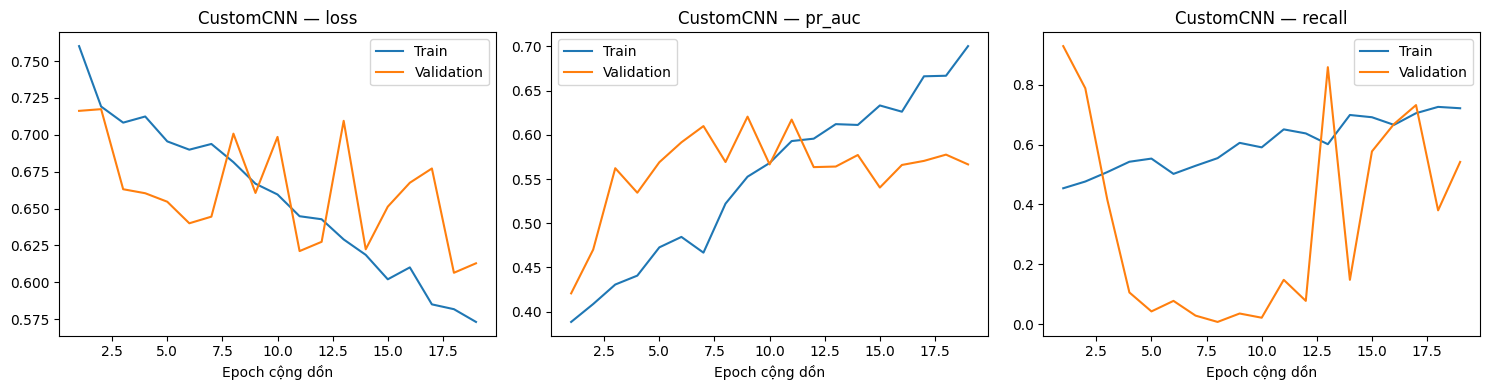

Đã lưu: /kaggle/working/brain_stroke_v4/models/CustomCNN_best.keras | val AP: 0.622229394254177 | Ngưỡng chốt trước: 0.5

HUẤN LUYỆN: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
110/110 - 20s - 178ms/step - accuracy: 0.5571 - loss: 0.7523 - pr_auc: 0.4498 - precision: 0.4318 - recall: 0.5233 - roc_auc: 0.5849 - val_accuracy: 0.6293 - val_loss: 0.6519 - val_pr_auc: 0.4982 - val_precision: 0.5273 - val_recall: 0.2042 - val_roc_auc: 0.6496 - learning_rate: 3.0000e-04
Epoch 2/10
110/110 - 10s - 92ms/step - accuracy: 0.6394 - loss: 0.6473 - pr_auc: 0.5777 - precision: 0.5213 - recall: 0.6271 - roc_auc: 0.7052 - val_accuracy: 0.6587 - val_loss: 0.6241 - val_pr_auc: 0.5532 - val_precision: 0.5875 - val_recall: 0.3310 - val_roc_auc: 0.7063 - learning_rate: 3.0000e-04
Epoch 3/10
110/110 - 10s - 92ms/step - accuracy: 0.6937 - loss: 0.5993 - pr_auc: 0.6563 - precision: 0.5830 - recall: 0.6812 - roc_auc: 0.7649 - val_accuracy: 0.6853 - val_loss: 0.6347 - val_pr_auc: 0.65

,split,setting,threshold,N,predicted_Normal,predicted_Stroke,score_min,score_max,score_std,Accuracy,F1,ROC_AUC,AP,log_loss
0,train_inference,predeclared,0.5,1750,1083,667,1.221317e-20,1.0,0.483578,0.994286,0.992492,0.999860,0.999776,0.018068
1,val,predeclared,0.5,375,238,137,7.669185e-19,1.0,0.469073,0.928000,0.903226,0.965877,0.947983,0.487049


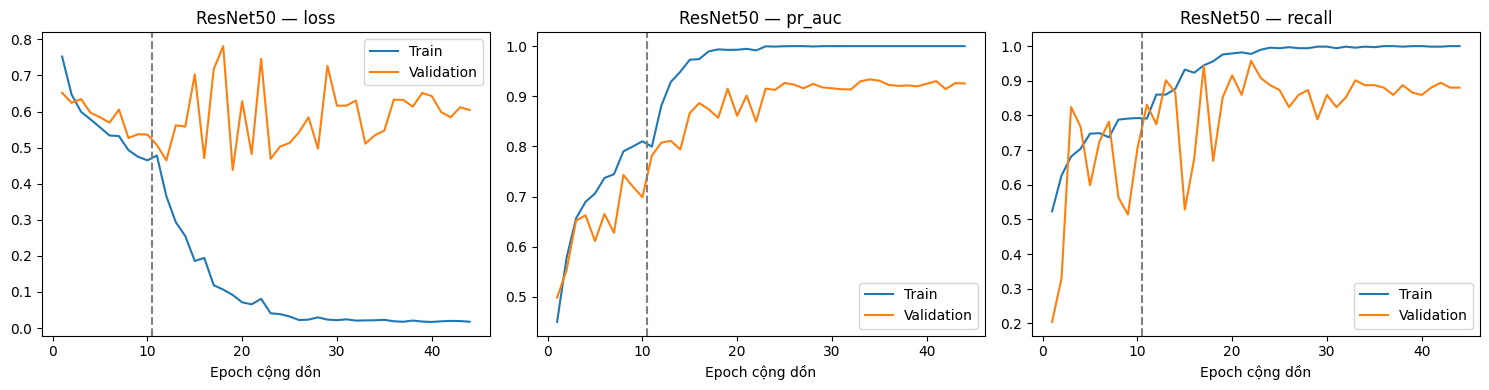

Đã lưu: /kaggle/working/brain_stroke_v4/models/ResNet50_best.keras | val AP: 0.9479829651158049 | Ngưỡng chốt trước: 0.5

HUẤN LUYỆN: VGG16
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
110/110 - 14s - 126ms/step - accuracy: 0.5297 - loss: 1.2215 - pr_auc: 0.4039 - precision: 0.4017 - recall: 0.4857 - roc_auc: 0.5397 - val_accuracy: 0.6560 - val_loss: 0.6940 - val_pr_auc: 0.5339 - val_precision: 0.5915 - val_recall: 0.2958 - val_roc_auc: 0.6806 - learning_rate: 3.0000e-04
Epoch 2/10
110/110 - 11s - 100ms/step - accuracy: 0.6074 - loss: 0.7683 - pr_auc: 0.5274 - precision: 0.4861 - recall: 0.5805 - roc_auc: 0.6484 - val_accuracy: 0.6693 - val_loss: 0.6379 - val_pr_auc: 0.5619 - val_precision: 0.6125 - val_recall: 0.3451 - val_roc_auc: 0.7159 - learning_rate: 3.0000e-04
Epoch 3/10
110/110 - 11s - 100ms/step - accuracy: 0.6486 - loss: 0.6581 - pr_auc: 0.6011 - precision: 0.5330 - recall: 0.6075 - roc_auc: 0.7069 - val_accuracy: 0.6773 - val_loss: 0.6039 - val_pr_auc: 0.611

,split,setting,threshold,N,predicted_Normal,predicted_Stroke,score_min,score_max,score_std,Accuracy,F1,ROC_AUC,AP,log_loss
0,train_inference,predeclared,0.5,1750,1105,645,6.460442e-19,1.0,0.477004,0.988571,0.984733,0.999891,0.999824,0.031021
1,val,predeclared,0.5,375,246,129,5.126334e-17,1.0,0.455242,0.906667,0.870849,0.973433,0.960623,0.377206


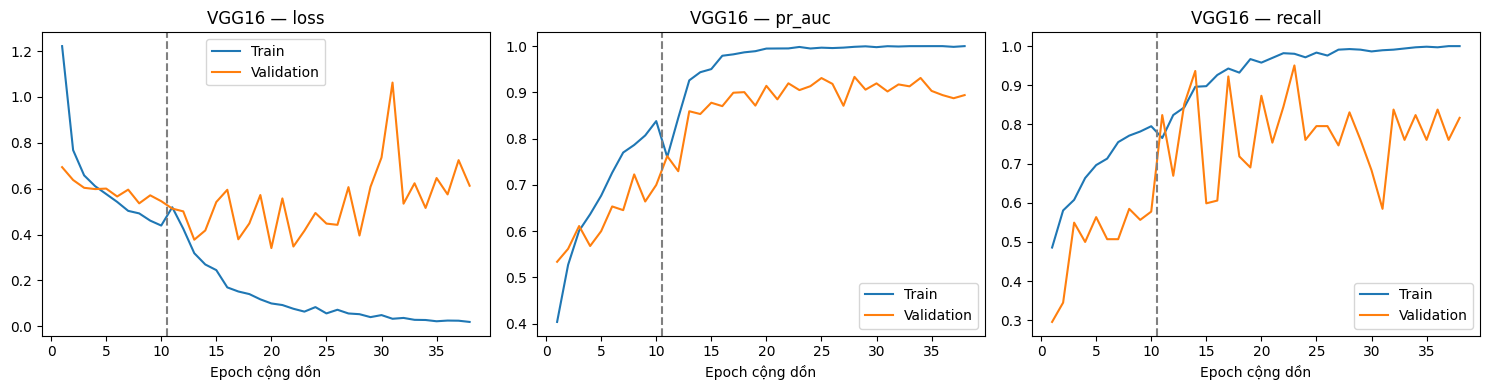

Đã lưu: /kaggle/working/brain_stroke_v4/models/VGG16_best.keras | val AP: 0.9606232593200434 | Ngưỡng chốt trước: 0.5

HUẤN LUYỆN: VGG19
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
110/110 - 16s - 143ms/step - accuracy: 0.5291 - loss: 1.2611 - pr_auc: 0.4261 - precision: 0.4020 - recall: 0.4902 - roc_auc: 0.5421 - val_accuracy: 0.6667 - val_loss: 0.6814 - val_pr_auc: 0.5565 - val_precision: 0.6164 - val_recall: 0.3169 - val_roc_auc: 0.6901 - learning_rate: 3.0000e-04
Epoch 2/10
110/110 - 12s - 113ms/step - accuracy: 0.6314 - loss: 0.7669 - pr_auc: 0.5515 - precision: 0.5128 - recall: 0.6015 - roc_auc: 0.6673 - val_accuracy: 0.6533 - val_loss: 0.6616 - val_pr_auc: 0.5079 - val_precision: 0.5492 - val_recall: 0.4718 - val_roc_auc: 0.6964 - learning_rate: 3.0000e-04
Epoch 3/10
110/110 - 13s - 116ms/step - accuracy: 0.6846 - loss: 0.6451 - pr_auc: 0.6097 - precision: 0.5752 - recall: 0.6496 - roc_auc: 0.7320 - val_accuracy: 0.6693 - val_loss: 0.6022 - val_pr_auc: 0.6200 -

,split,setting,threshold,N,predicted_Normal,predicted_Stroke,score_min,score_max,score_std,Accuracy,F1,ROC_AUC,AP,log_loss
0,train_inference,predeclared,0.5,1750,1089,661,1.973108e-17,1.0,0.482621,0.997714,0.996983,1.000000,1.000000,0.004273
1,val,predeclared,0.5,375,242,133,1.019345e-17,1.0,0.458329,0.933333,0.909091,0.984162,0.973929,0.244591


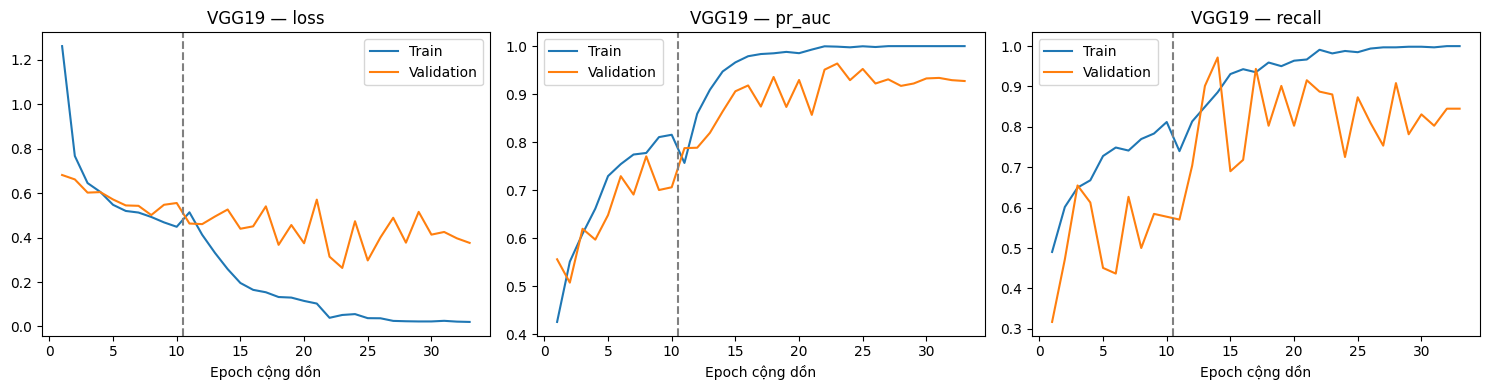

Đã lưu: /kaggle/working/brain_stroke_v4/models/VGG19_best.keras | val AP: 0.9739285370782076 | Ngưỡng chốt trước: 0.5


,Model,seconds,params,selected_stage,val_AP,threshold
0,CustomCNN,395.748946,1208161,CustomCNN_cnn,0.622229,0.5
1,ResNet50,713.213396,23850113,ResNet50_fine,0.947983,0.5
2,VGG16,595.471648,14780481,VGG16_fine,0.960623,0.5
3,VGG19,628.049195,20090177,VGG19_fine,0.973929,0.5


In [7]:
if (OUT/'RUN_STARTED.json').exists():
    raise RuntimeError('Đã bắt đầu train trong OUT này. Không chạy lại Cell 7; đổi OUT và khởi động lại nếu muốn thí nghiệm mới.')
(OUT/'RUN_STARTED.json').write_text(json.dumps({'started_utc':pd.Timestamp.now(tz='UTC').isoformat()}))
model_dir = OUT/'models'; model_dir.mkdir(exist_ok=True)
stage_dir = OUT/'stage_checkpoints'; stage_dir.mkdir(exist_ok=True)
selected, training_rows = {}, []
y_val = val_df.label.to_numpy()
for name in MODELS_TO_TRAIN:
    print('\n'+'='*55+'\nHUẤN LUYỆN:',name)
    tf.keras.backend.clear_session(); gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    train_ds = make_ds(train_df,True,seed=SEED)
    start = time.perf_counter()
    history_parts = []
    candidates = []
    if name=='CustomCNN':
        model = build_custom()
        compile_model(model,3e-4)
        stage_path = stage_dir/f'{name}_cnn.keras'
        hist = model.fit(train_ds,validation_data=val_ds,epochs=EPOCHS_CNN,
            class_weight=CLASS_WEIGHT,shuffle=False,callbacks=callbacks_for(stage_path,OUT/f'{name}_cnn_log.csv',10),verbose=2)
        history_parts.append(('cnn',hist.history)); candidates.append(stage_path)
        del model
    else:
        model,base_name = build_transfer(name)
        compile_model(model,3e-4)
        head_path = stage_dir/f'{name}_head.keras'
        hist = model.fit(train_ds,validation_data=val_ds,epochs=EPOCHS_HEAD,
            class_weight=CLASS_WEIGHT,shuffle=False,callbacks=callbacks_for(head_path,OUT/f'{name}_head_log.csv',5),verbose=2)
        history_parts.append(('head',hist.history)); candidates.append(head_path)
        del model; gc.collect()
        model = tf.keras.models.load_model(head_path,compile=False)
        unfreeze_last_blocks(model,name,base_name)
        compile_model(model,1e-5)  # Optimizer mới cho giai đoạn fine-tuning.
        print('Số tham số trainable khi fine-tuning:',sum(int(np.prod(w.shape)) for w in model.trainable_weights))
        fine_path = stage_dir/f'{name}_fine.keras'
        hist = model.fit(train_ds,validation_data=val_ds,epochs=EPOCHS_FINE,
            class_weight=CLASS_WEIGHT,shuffle=False,callbacks=callbacks_for(fine_path,OUT/f'{name}_fine_log.csv',10),verbose=2)
        history_parts.append(('fine',hist.history)); candidates.append(fine_path)
        del model
    stage_scores = []
    for path in candidates:
        tf.keras.backend.clear_session(); gc.collect()
        candidate = tf.keras.models.load_model(path,compile=False)
        prob = checked_predict(candidate,val_ds,len(val_df))
        stage_scores.append(dict(stage=path.stem,checkpoint=str(path),val_AP=float(average_precision_score(y_val,prob))))
        del candidate
    pd.DataFrame(stage_scores).to_csv(OUT/f'{name}_stage_selection.csv',index=False)
    best = max(stage_scores,key=lambda row: row['val_AP'])
    tf.keras.backend.clear_session(); gc.collect()
    model = tf.keras.models.load_model(best['checkpoint'],compile=False)
    prob = checked_predict(model,val_ds,len(val_df))
    threshold = float(config['decision_threshold'])  # Không phụ thuộc nhãn hoặc điểm validation/test.
    assert threshold == DECISION_THRESHOLD, 'Cấu hình ngưỡng đã đổi sau Cell 6; chạy thí nghiệm mới.'
    
    # Không chọn model bằng train. Đo khi augmentation tắt để chẩn đoán train/val nhất quán.
    train_prob = checked_predict(model,train_eval_ds,len(train_df))
    diag_rows = []
    for split_name,yy,pp in [('train_inference',train_df.label.to_numpy(),train_prob),('val',y_val,prob)]:
        for setting,tt in [('predeclared',threshold)]:
            pred = (pp>tt).astype(int)
            diag_rows.append(dict(split=split_name,setting=setting,threshold=tt,
                N=len(yy),predicted_Normal=int(sum(pred==0)),predicted_Stroke=int(sum(pred==1)),
                score_min=float(pp.min()),score_max=float(pp.max()),score_std=float(pp.std()),
                Accuracy=float(accuracy_score(yy,pred)),F1=float(f1_score(yy,pred,zero_division=0)),
                ROC_AUC=float(roc_auc_score(yy,pp)),AP=float(average_precision_score(yy,pp)),
                log_loss=float(log_loss(yy,pp,labels=[0,1]))))
            if len(np.unique(pred))==1:
                print('CẢNH BÁO:',name,split_name,setting,'đang dự đoán một lớp; không coi recall cao là thành công.')
    pd.DataFrame(diag_rows).to_csv(OUT/f'{name}_train_val_diagnostics.csv',index=False)
    display(pd.DataFrame(diag_rows))
    val_pred = val_df[['relpath','label']].copy()
    val_pred['stroke_score'] = prob
    val_pred['threshold'] = threshold
    val_pred['prediction'] = (prob>threshold).astype(int)
    val_pred.to_csv(OUT/f'{name}_val_predictions.csv',index=False)
    dest = model_dir/f'{name}_best.keras'
    model.save(dest)
    # Kiểm tra round-trip bằng batch dữ liệu thật, không dùng ảnh test.
    probe = next(iter(val_ds))[0]
    before = model(probe,training=False).numpy()
    loaded = tf.keras.models.load_model(dest,compile=False)
    np.testing.assert_allclose(before,loaded(probe,training=False).numpy(),rtol=1e-5,atol=1e-6)
    params = model.count_params()
    selected[name] = dict(path=str(dest),threshold=threshold,val_AP=best['val_AP'],
                          selected_stage=best['stage'],params=params)
    training_rows.append(dict(Model=name,seconds=time.perf_counter()-start,params=params,
                              selected_stage=best['stage'],val_AP=best['val_AP'],threshold=threshold))
    (OUT/'selected_models.json').write_text(json.dumps(selected,indent=2),encoding='utf-8')
    pd.DataFrame(training_rows).to_csv(OUT/'training_summary.csv',index=False)
    history = pd.concat([pd.DataFrame(h).assign(stage=stage,epoch_in_stage=np.arange(1,len(h['loss'])+1))
                         for stage,h in history_parts],ignore_index=True)
    history.to_csv(OUT/f'{name}_history.csv',index=False)
    fig,axs = plt.subplots(1,3,figsize=(15,4))
    for ax,metric in zip(axs,['loss','pr_auc','recall']):
        ax.plot(np.arange(1,len(history)+1),history[metric],label='Train')
        ax.plot(np.arange(1,len(history)+1),history['val_'+metric],label='Validation')
        if len(history_parts)>1: ax.axvline(len(history_parts[0][1]['loss'])+0.5,color='gray',linestyle='--')
        ax.set_title(name+' — '+metric); ax.set_xlabel('Epoch cộng dồn'); ax.legend()
    plt.tight_layout(); plt.savefig(OUT/f'{name}_learning_curves.png'); plt.show()
    print('Đã lưu:',dest,'| val AP:',best['val_AP'],'| Ngưỡng chốt trước:',threshold)
    del model,loaded,probe,before; gc.collect()
display(pd.DataFrame(training_rows))


## Cell 8 — Test sau khi chốt model, công bố mọi kết quả
Mỗi model chỉ có **một hàng** với ngưỡng chốt trước (mặc định 0,5).
Accuracy, balanced accuracy, Precision, Recall, Specificity, F1, MCC, FPR, TN/FP/FN/TP;
thêm ROC-AUC/AP tính trực tiếp từ điểm, không tìm ngưỡng tốt nhất.
Lưu điểm từng ảnh để tính lại số đo. Baseline đoán lớp train chiếm đa số được báo cáo riêng.
Chọn kiến trúc bằng validation AP trước khi predict test. Không chọn mạng theo điểm test đẹp nhất.


Kiến trúc được chọn BẰNG VALIDATION: VGG19
BASELINE ĐỐI CHIẾU (không phải neural model): {'method': 'always predict majority class learned from TRAIN only', 'predicted_class': 'Normal', 'N': 376, 'Accuracy': 0.6196808510638298, 'Balanced_accuracy': 0.5, 'F1_Stroke': 0.0}


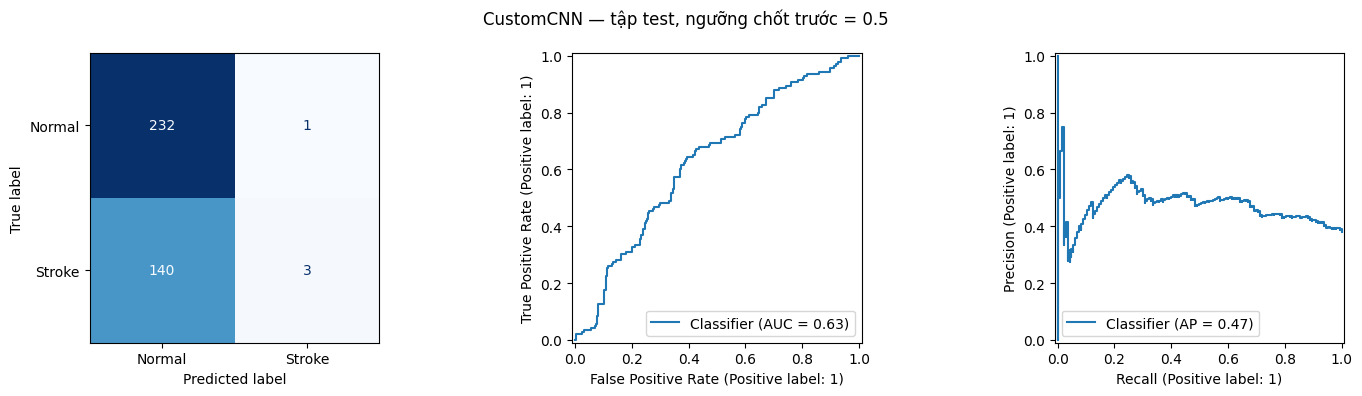

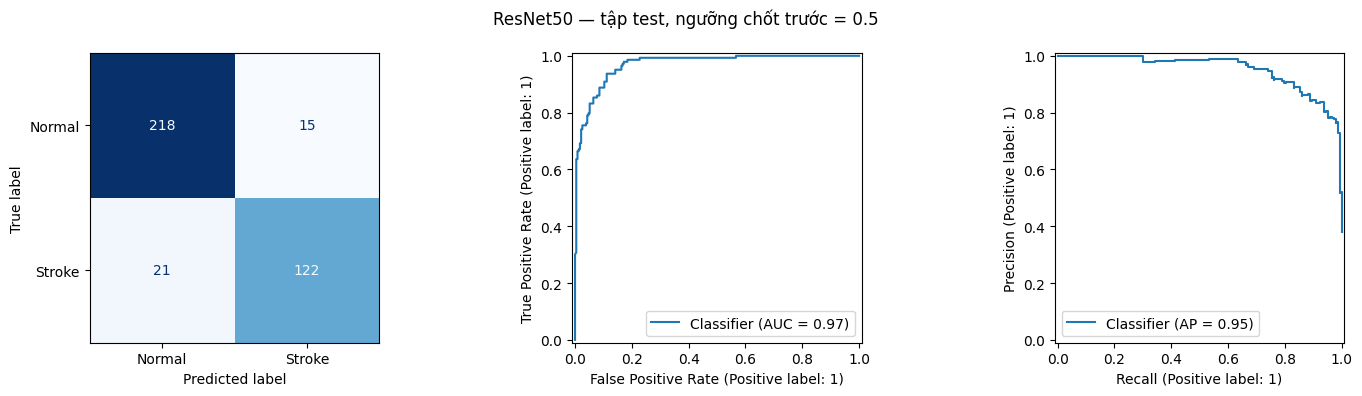

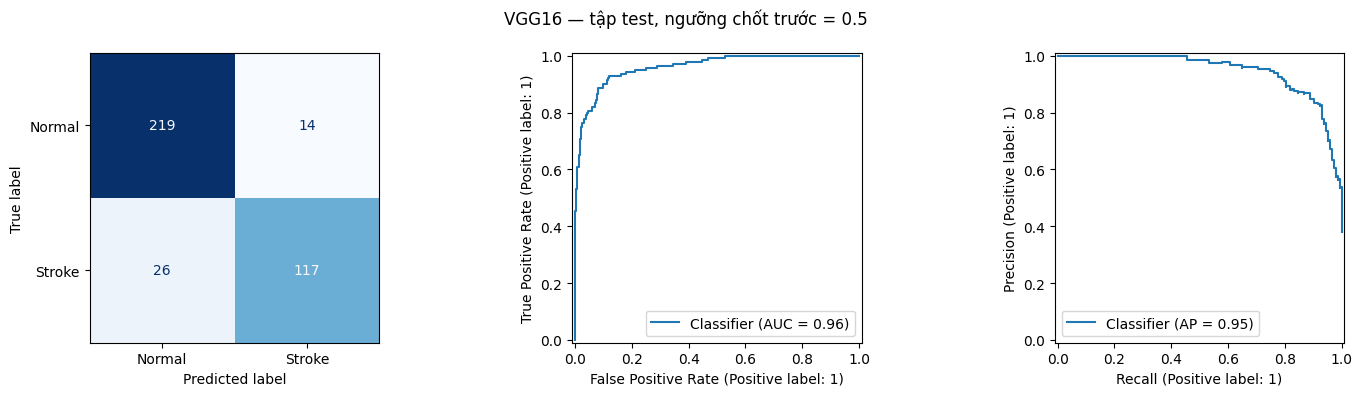

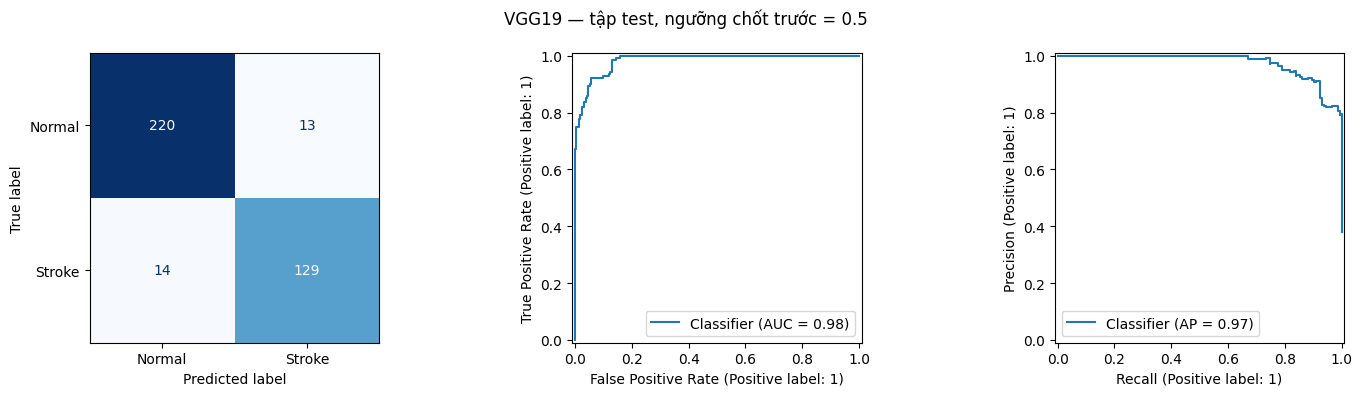

,Model,Setting,Threshold,Accuracy,Balanced_accuracy,Precision_Stroke,Recall_Stroke,Specificity_Normal,F1_Stroke,MCC,ROC_AUC,Average_precision,FPR,TN,FP,FN,TP,N
0,CustomCNN,predeclared,0.5,0.625000,0.508344,0.750000,0.020979,0.995708,0.040816,0.078964,0.630931,0.472045,0.004292,232,1,140,3,376
1,ResNet50,predeclared,0.5,0.904255,0.894385,0.890511,0.853147,0.935622,0.871429,0.795677,0.969822,0.952885,0.064378,218,15,21,122,376
2,VGG16,predeclared,0.5,0.893617,0.879048,0.893130,0.818182,0.939914,0.854015,0.772416,0.961073,0.946708,0.060086,219,14,26,117,376
3,VGG19,predeclared,0.5,0.928191,0.923152,0.908451,0.902098,0.944206,0.905263,0.847462,0.983763,0.974956,0.055794,220,13,14,129,376


Chỉ số tính từ nhãn và điểm model; mỗi model có một ngưỡng chốt trước. Không tìm ngưỡng tối đa F1.


In [8]:
selected = json.loads((OUT/'selected_models.json').read_text())
assert set(selected)==set(MODELS_TO_TRAIN), 'Chưa hoàn tất các model đã cấu hình.'
deployment_name = max(selected,key=lambda n:selected[n]['val_AP'])
(OUT/'deployment_choice.json').write_text(json.dumps({'model':deployment_name,
    'selection_rule':'highest validation AP; never selected by test','details':selected[deployment_name]},indent=2))
print('Kiến trúc được chọn BẰNG VALIDATION:',deployment_name)

def metric_row(y,p,threshold):
    pred = (p>threshold).astype(int)
    tn,fp,fn,tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(Threshold=float(threshold),Accuracy=float(accuracy_score(y,pred)),
        Balanced_accuracy=float(balanced_accuracy_score(y,pred)),
        Precision_Stroke=float(precision_score(y,pred,zero_division=0)),
        Recall_Stroke=float(recall_score(y,pred,zero_division=0)),
        Specificity_Normal=float(tn/(tn+fp)),F1_Stroke=float(f1_score(y,pred,zero_division=0)),
        MCC=float(matthews_corrcoef(y,pred)),ROC_AUC=float(roc_auc_score(y,p)),
        Average_precision=float(average_precision_score(y,p)),FPR=float(fp/(tn+fp)),
        TN=int(tn),FP=int(fp),FN=int(fn),TP=int(tp),N=int(len(y)))

rows = []
y_test = test_df.label.to_numpy()
majority_label = int(train_df.label.value_counts().idxmax())
majority_pred = np.full(len(y_test),majority_label,dtype=int)
baseline = dict(method='always predict majority class learned from TRAIN only',
    predicted_class=['Normal','Stroke'][majority_label],N=len(y_test),
    Accuracy=float(accuracy_score(y_test,majority_pred)),
    Balanced_accuracy=float(balanced_accuracy_score(y_test,majority_pred)),
    F1_Stroke=float(f1_score(y_test,majority_pred,zero_division=0)))
(OUT/'majority_baseline.json').write_text(json.dumps(baseline,indent=2))
print('BASELINE ĐỐI CHIẾU (không phải neural model):',baseline)
for name,info in selected.items():
    tf.keras.backend.clear_session(); gc.collect()
    model = tf.keras.models.load_model(info['path'],compile=False)
    p = checked_predict(model,test_ds,len(test_df))
    threshold = info['threshold']
    assert threshold == config['decision_threshold'], 'Ngưỡng model khác chính sách đã chốt.'
    for setting,t in [('predeclared',threshold)]:
        rows.append(dict(Model=name,Setting=setting,**metric_row(y_test,p,t)))
    predictions = test_df[['relpath','label','class','group_id']].copy()
    if 'patient_id' in test_df: predictions['patient_id'] = test_df.patient_id
    predictions['stroke_score'] = p
    predictions['threshold'] = threshold
    predictions['prediction'] = (p>threshold).astype(int)
    predictions['correct'] = predictions.prediction.eq(predictions.label)
    predictions.to_csv(OUT/f'{name}_test_predictions.csv',index=False)
    if predictions.prediction.nunique()==1:
        print('CẢNH BÁO:',name,'dự đoán một lớp trên test ở ngưỡng đã chốt trước.')
    report = classification_report(y_test,predictions.prediction,labels=[0,1],
                                  target_names=['Normal','Stroke'],output_dict=True,zero_division=0)
    (OUT/f'{name}_classification_report.json').write_text(json.dumps(report,indent=2))
    fig,axs = plt.subplots(1,3,figsize=(15,4))
    ConfusionMatrixDisplay.from_predictions(y_test,predictions.prediction,labels=[0,1],
        display_labels=['Normal','Stroke'],cmap='Blues',ax=axs[0],colorbar=False)
    RocCurveDisplay.from_predictions(y_test,p,ax=axs[1])
    PrecisionRecallDisplay.from_predictions(y_test,p,ax=axs[2])
    fig.suptitle(name+' — tập test, ngưỡng chốt trước = ' + str(threshold) + '')
    plt.tight_layout(); plt.savefig(OUT/f'{name}_test_metrics.png'); plt.show()
    del model
comparison = pd.DataFrame(rows)
comparison.to_csv(OUT/'model_comparison.csv',index=False)
display(comparison)  # Không sắp xếp để chọn model theo test.
print('Chỉ số tính từ nhãn và điểm model; mỗi model có một ngưỡng chốt trước. Không tìm ngưỡng tối đa F1.')


## Cell 9 — Xem ảnh sai để kiểm tra lỗi, không dùng để tinh chỉnh lần chạy này
Hiển thị tối đa 8 ảnh sai của kiến trúc đã chọn bằng validation. Đây là phân tích sau đánh giá.
Nếu dùng test để sửa mô hình ở vòng sau thì test đó trở thành dữ liệu phát triển;
cần một tập đánh giá độc lập khác để công bố kết quả cuối.


Số ảnh sai trên test: 27 / 376


,relpath,label,class,group_id,stroke_score,threshold,prediction,correct
323,Stroke/86 (1).jpg,1,Stroke,2185,0.001011,0.5,0,False
325,Stroke/86 (36).jpg,1,Stroke,2210,0.002134,0.5,0,False
280,Stroke/74 (5).jpg,1,Stroke,1856,0.009271,0.5,0,False
233,Stroke/58 (10).jpg,1,Stroke,1552,0.009621,0.5,0,False
235,Stroke/58 (20).jpg,1,Stroke,1561,0.010141,0.5,0,False
236,Stroke/58 (21).jpg,1,Stroke,1562,0.012137,0.5,0,False
355,Stroke/92 (12).jpg,1,Stroke,2376,0.013491,0.5,0,False
295,Stroke/77 (40).jpg,1,Stroke,1945,0.015740,0.5,0,False
255,Stroke/68 (8).jpg,1,Stroke,1667,0.020192,0.5,0,False
347,Stroke/91 (17).jpg,1,Stroke,2347,0.023798,0.5,0,False


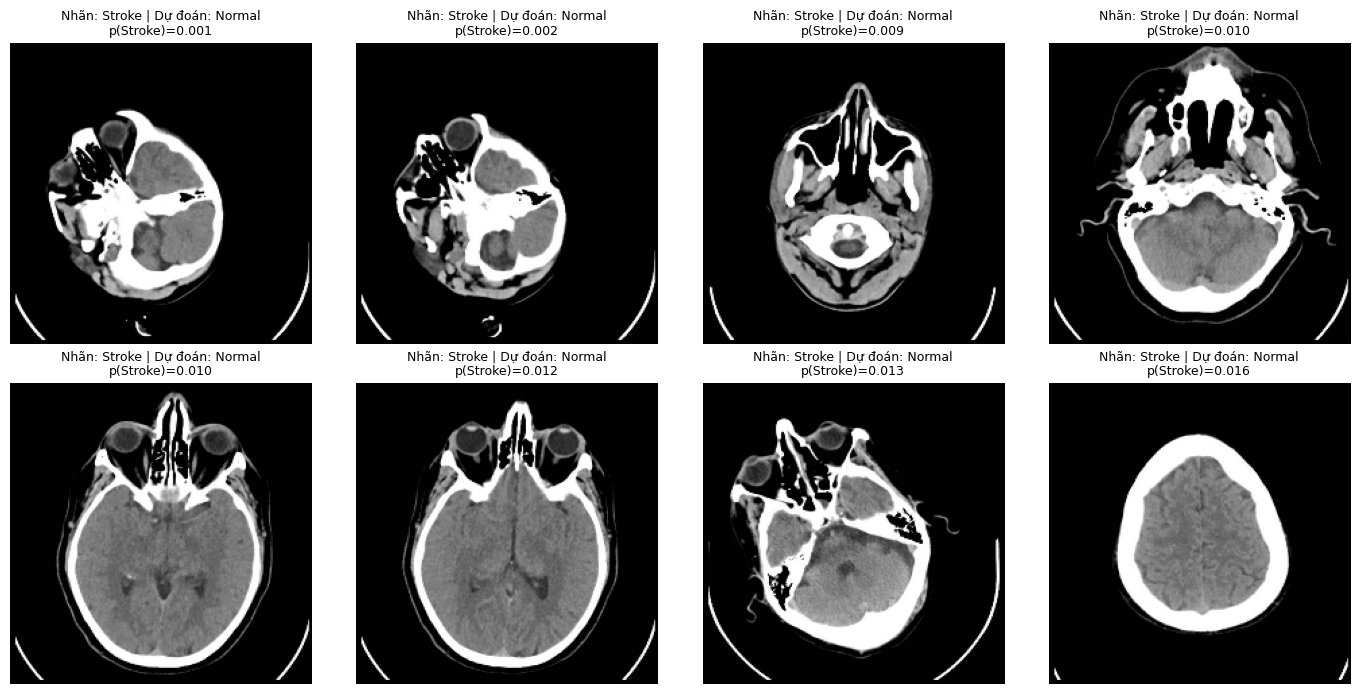

In [9]:
errors = pd.read_csv(OUT/f'{deployment_name}_test_predictions.csv')
errors = errors[errors.label!=errors.prediction].sort_values('stroke_score')
print('Số ảnh sai trên test:',len(errors),'/',len(test_df))
display(errors.head(20))
if len(errors):
    take = errors.head(8)
    fig,axs = plt.subplots(2,4,figsize=(14,7))
    lookup = test_df.set_index('relpath').path.to_dict()
    for ax in axs.ravel(): ax.axis('off')
    for ax,(_,row) in zip(axs.ravel(),take.iterrows()):
        im,_ = decode_img(lookup[row.relpath],row.label)
        ax.imshow(tf.cast(tf.clip_by_value(im,0,255),tf.uint8))
        ax.set_title(f"Nhãn: {['Normal','Stroke'][int(row.label)]} | Dự đoán: {['Normal','Stroke'][int(row.prediction)]}\np(Stroke)={row.stroke_score:.3f}",fontsize=9)
    plt.tight_layout(); plt.savefig(OUT/'misclassified_examples.png'); plt.show()


## Cell 10 — Xuất model và mã chạy local đồng nhất
Chạy **cả ba ô code dưới đây**. `.keras` nhận RGB float32 0–255; preprocessing nằm trong model.
`model_config.json` ghi đúng ngưỡng đã chốt trước, mặc định 0,5 cho cả bốn model;
không dùng config/ngưỡng tối ưu từ V3. Script hỗ trợ CustomCNN, ResNet50, VGG16, VGG19.
Web cũ chỉ có ba model cần cập nhật nếu muốn chọn VGG19.
`stroke_score` là điểm sigmoid chưa hiệu chuẩn, không diễn giải thành xác suất mắc bệnh thực tế.


In [10]:
local_config = {'configuration_source':'brain_stroke_v4; predeclared threshold; preprocessing inside saved models', 'models':{}}
for name,info in selected.items():
    assert info['threshold'] == config['decision_threshold']
    local_config['models'][name] = dict(path=f'models/{name}_best.keras',
        class_names=['Normal','Stroke'],preprocessing='raw_0_255',
        interpolation='tensorflow_bilinear',apply_exif_orientation=False,
        output_mode='probabilities',binary_output_index=1,threshold=info['threshold'],
        dynamic_input_size=list(IMG_SIZE))
(OUT/'model_config.json').write_text(json.dumps(local_config,indent=2,ensure_ascii=False),encoding='utf-8')


1769

In [11]:
INFERENCE_SOURCE = '"""Chạy: python predict_local.py --image /path/anh.jpg --model ResNet50\nCần TensorFlow, Pillow, NumPy; đặt script cạnh model_config.json và folder models.\n"""\nimport argparse, io, json\nfrom pathlib import Path\nimport numpy as np\nfrom PIL import Image\nimport tensorflow as tf\n\ndef image_tensor(path, size=(224,224)):\n    raw = Path(path).read_bytes()\n    with Image.open(io.BytesIO(raw)) as im:\n        if getattr(im,\'n_frames\',1)!=1 or im.mode in (\'I\',\'F\') or im.mode.startswith(\'I;16\'):\n            raise ValueError(\'Cần ảnh tĩnh 8-bit. Không tự ép ảnh 16-bit.\')\n        im.load()\n        if im.format not in (\'JPEG\',\'PNG\',\'BMP\'):\n            buffer = io.BytesIO()\n            im.convert(\'RGB\').save(buffer,format=\'PNG\')\n            raw = buffer.getvalue()\n    x = tf.io.decode_image(raw,channels=3,expand_animations=False)\n    x = tf.image.resize(x,size,method=\'bilinear\',antialias=False)\n    return tf.cast(x,tf.float32)[None,...]\n\ndef predict(image, model_name, root=None):\n    root = Path(root) if root else Path(__file__).resolve().parent\n    config = json.loads((root/\'model_config.json\').read_text(encoding=\'utf-8\'))[\'models\'][model_name]\n    model = tf.keras.models.load_model(root/config[\'path\'],compile=False)\n    size = tuple(int(v) for v in model.input_shape[1:3])\n    result = model(image_tensor(image,size),training=False).numpy()\n    if result.shape!=(1,1) or not np.isfinite(result).all() or not 0<=float(result[0,0])<=1:\n        raise ValueError(\'Output không hợp lệ.\')\n    p = float(result[0,0]); t = float(config[\'threshold\'])\n    return dict(model=model_name,stroke_score=p,normal_score=1-p,threshold=t,\n                prediction=\'Stroke\' if p>t else \'Normal\')\n\nif __name__==\'__main__\':\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'--image\',required=True)\n    parser.add_argument(\'--model\',choices=[\'CustomCNN\',\'ResNet50\',\'VGG16\',\'VGG19\'],default=\'ResNet50\')\n    args = parser.parse_args()\n    print(json.dumps(predict(args.image,args.model),ensure_ascii=False,indent=2))\n'
(OUT/'predict_local.py').write_text(INFERENCE_SOURCE,encoding='utf-8')
print('Đã ghi predict_local.py')


Đã ghi predict_local.py


In [12]:
# Kiểm tra pipeline local bằng ảnh validation thật và model đã xuất.
import importlib.util
spec = importlib.util.spec_from_file_location('stroke_predict_v4',OUT/'predict_local.py')
predict_module = importlib.util.module_from_spec(spec); spec.loader.exec_module(predict_module)
probe_path = val_df.iloc[0].path
expected,_ = decode_img(probe_path,val_df.iloc[0].label)
np.testing.assert_allclose(expected.numpy(),predict_module.image_tensor(probe_path,IMG_SIZE)[0].numpy(),rtol=0,atol=0)
print('Tensor local và Kaggle giống nhau trên ảnh validation đã kiểm tra.')
print(predict_module.predict(probe_path,deployment_name,root=OUT))
# Lưu phiên bản để cài local đúng phiên bản huấn luyện; không tự cài lại môi trường Kaggle.
req = '\n'.join(['tensorflow=='+tf.__version__,'numpy=='+np.__version__,
                'Pillow=='+Image.__version__])+'\n'
(OUT/'requirements_local.txt').write_text(req,encoding='utf-8')
hashes = {}
for p in model_dir.glob('*.keras'):
    h = hashlib.sha256()
    with p.open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    hashes[p.name] = h.hexdigest()
(OUT/'model_sha256.json').write_text(json.dumps(hashes,indent=2))
readme = f"""Ngưỡng thực tế đã chốt trước: {config['decision_threshold']}\nKẾT QUẢ HUẤN LUYỆN THỰC TẾ — BRAIN STROKE V4
models/*_best.keras: Các model cuối chọn bằng validation.
model_config.json: mapping nhãn, pipeline và ngưỡng chốt trước, mặc định 0.5 cho cả bốn model.
predict_local.py: inference local đúng pipeline, không chia 255 bên ngoài model.
requirements_local.txt: phiên bản TensorFlow/NumPy/Pillow của lần chạy.
model_comparison.csv: số đo test ở một ngưỡng chốt trước, mặc định 0.5.
*_test_predictions.csv: điểm, nhãn và kết quả từng ảnh để kiểm chứng phép đo.
split_manifest.csv: cách chia, hash pixel, nhóm, relpath của dữ liệu.
training_summary.csv: thời gian thực đo, tham số, stage, validation AP.
Không chứa dữ liệu ảnh gốc. converted/extracted_data và checkpoint trung gian không nằm trong ZIP.
Chưa có patient ID thì chưa thể khẳng định độc lập bệnh nhân.
Đây là mô hình nghiên cứu phân loại nhãn dataset, không phải công cụ chẩn đoán lâm sàng.
"""
(OUT/'README_KET_QUA.txt').write_text(readme,encoding='utf-8')
archive_path = OUT.parent/'brain_stroke_v4_results.zip'
with zipfile.ZipFile(archive_path,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=4) as z:
    for p in sorted(OUT.rglob('*')):
        rel = p.relative_to(OUT)
        if p.is_file() and not set(rel.parts)&{'extracted_data','converted','stage_checkpoints','__pycache__'}:
            z.write(p,arcname=rel.as_posix())
print('TẢI FILE:',archive_path)
print('Kích thước ZIP thực tế (MiB):',round(archive_path.stat().st_size/1024**2,2))
from IPython.display import FileLink
display(FileLink(str(archive_path)))


Tensor local và Kaggle giống nhau trên ảnh validation đã kiểm tra.
{'model': 'VGG19', 'stroke_score': 2.4910972840075374e-08, 'normal_score': 0.9999999750890272, 'threshold': 0.5, 'prediction': 'Normal'}
TẢI FILE: /kaggle/working/brain_stroke_v4_results.zip
Kích thước ZIP thực tế (MiB): 214.23


/kaggle/working/brain_stroke_v4_results.zip

## Đọc kết quả, tải model và sử dụng lại
- `training_summary.csv`: thời gian, tham số, stage và validation AP; không phải bảng test.
- `*_train_val_diagnostics.csv`: chênh lệch train/val khi tắt augmentation, số dự đoán mỗi lớp,
  score min/max/std, loss và chỉ số. Train tốt nhưng val thấp gợi ý khả năng khái quát hạn chế.
- `model_comparison.csv`: bốn hàng test cho bốn model ở ngưỡng chốt trước.
  Xem Recall cùng Specificity/FP/FN; Accuracy cao chưa đủ khi model chỉ đoán một lớp.
- `*_test_predictions.csv`: nhãn gốc, điểm thật, ngưỡng, dự đoán từng ảnh.
- `split_manifest.csv`: phép chia theo hash/nhóm để tái lập; thiếu patient ID chưa độc lập bệnh nhân.
- `models/*_best.keras`: full model; giữ cùng `model_config.json` và `predict_local.py`.

Sau Cell 10 tải `/kaggle/working/brain_stroke_v4_results.zip`. ZIP không chứa ảnh gốc,
chứa model, báo cáo, config, script, requirements và hash model. Trong Miniconda:
```bash
pip install -r requirements_local.txt
python predict_local.py --image /duong/dan/anh.jpg --model VGG19
```
Môi trường Python cần tương thích phiên bản TensorFlow ghi trong requirements.
Không chia 255 ngoài model; không tự crop/đổi tương phản khi chạy local.

### Cách diễn giải đúng
Không bắt buộc mọi mô hình phải đạt điểm cao. Giữ nguyên kết quả kém và phân tích nguyên nhân;
không đổi nhãn, đổi seed, chọn ảnh dễ hay ngưỡng sau khi xem test để cải thiện bảng điểm.
Class weight tác động loss trong huấn luyện, không thay thế việc học và không tạo Accuracy sẵn.
Ngưỡng 0,5 không bảo đảm tối ưu; nghiên cứu ngưỡng là một thí nghiệm riêng phải có mục tiêu rõ ràng
và validation thích hợp. File này không tìm ngưỡng. Cần dữ liệu bệnh nhân ngoài chưa xem để kiểm định cuối.

### Tài liệu chính thức
- [TensorFlow shuffle](https://www.tensorflow.org/api_docs/python/tf/data/Dataset#shuffle)
- [Keras transfer learning](https://keras.io/guides/transfer_learning/)
- [Keras VGG preprocessing](https://keras.io/api/applications/vgg/)
- [scikit-learn: ngưỡng quyết định](https://scikit-learn.org/stable/modules/classification_threshold.html)

### Kiểm tra phần mềm trước khi bàn giao
Notebook không có output huấn luyện sẵn. Các kiểm tra phần mềm dùng dữ liệu tạm và cấu hình nhỏ,
không đo hiệu năng trên dataset thật và không tạo số liệu để đưa vào báo cáo nghiên cứu.

Đã kiểm tra trên TensorFlow 2.20.0 CPU: ảnh tạm 64×64, batch 2, một batch train mỗi stage;
trọng số ngẫu nhiên chỉ trong kiểm tra phần mềm (bản giao vẫn ImageNet). Cả bốn kiến trúc qua
train/fine-tuning và lưu–nạp checkpoint. Không dùng các điểm kiểm tra đó làm kết quả nghiên cứu.
Tính lại metrics từ CSV dự đoán, quy tắc bằng ngưỡng giữa Keras/báo cáo/local,
pipeline đọc ảnh local và xuất ZIP cũng đã qua kiểm tra. Không có kết quả thử lưu trong notebook.
